<a href="https://colab.research.google.com/github/Bhavesh1412/CSL701-CS33_Machine-Learning-Lab/blob/main/Experiment_6_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name:** Bhavesh Chandrakant Mundye
**Roll No:** CS33

**Aim**
To implement Support Vector Machine (SVM) for classification of the Iris dataset and visualize its decision boundary and compare it with a normal linear classification boundary.

## Objectives

1. To understand the concept of Support Vector Machine.
2. To implement SVM using Python.
3. To visualize the SVM decision boundary.
4. To identify the support vectors.
5. To compare the SVM boundary with a normal linear classification boundary.
6. To evaluate the performance of the classifiers.

# Relevant Theory

### Support Vector Machine

Support Vector Machine (SVM) is a supervised machine learning algorithm used for classification.

SVM finds a decision boundary that separates different classes while trying to maximize the distance, called the **margin**, between the classes.

The points closest to the decision boundary are called **support vectors**.

For a linear SVM, the decision boundary can be represented as:

$$
w^T x + b = 0
$$

where:

- $w$ = weight vector
- $x$ = input features
- $b$ = bias


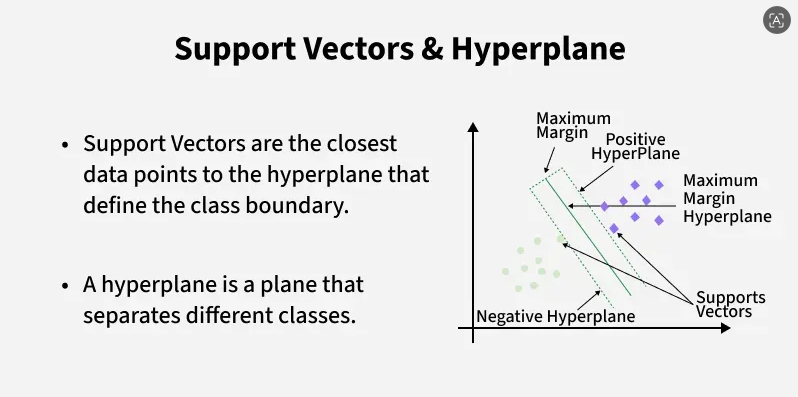
### Kernel

SVM can use different kernels to create decision boundaries.

Common kernels are:

- Linear
- Polynomial
- RBF
- Sigmoid

In this experiment, we mainly use the **Linear SVM** and **RBF SVM**.

---

# Dataset Information

Get the IRIS dataset from Kaggle using below link

https://www.kaggle.com/datasets/uciml/iris

The Iris dataset contains measurements of Iris flowers belonging to three classes:

- Iris-setosa
- Iris-versicolor
- Iris-virginica

The four features are:

- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

For visualization, we will use:

**Petal Length and Petal Width.**

# Task 1: Import Libraries and Load Dataset

Load the Iris dataset.

---

In [1]:
# Import libraries and load dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('Iris.csv')

print(df.head())

Saving Iris.csv to Iris.csv
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


# Task 2: Explore the Dataset

In [2]:
# Explore the dataset

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Dataset Shape:
(150, 6)

Column Names:
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm

# Task 3: Select Features and Target

Remove the `Id` column.

Select Remaining Features

In [3]:
# Select features and target

df = df.drop('Id', axis=1)

X = df.drop('Species', axis=1)
y = df['Species']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
0            5.1           3.5            1.4           0.2
1            4.9           3.0            1.4           0.2
2            4.7           3.2            1.3           0.2
3            4.6           3.1            1.5           0.2
4            5.0           3.6            1.4           0.2

Target:
0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: Species, dtype: object


# Task 4: Split and Scale the Data

Divide the dataset into training and testing sets.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Implement Linear SVM
svm_model = SVC(kernel='linear')

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

print("Predicted values:")
print(y_pred)

Predicted values:
['Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-setosa' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-virginica' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-setosa' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-virginica'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa']


# Task 5: Implement Linear SVM

Create an SVM model using a **linear kernel**.

Make predictions.

In [8]:
# Implement Linear SVM

svm_model = SVC(kernel='linear')

svm_model.fit(X_train, y_train)

y_pred = svm_model.predict(X_test)

print("Predicted values:")
print(y_pred)

Predicted values:
['Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-virginica' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-setosa' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-virginica' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-setosa' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-virginica'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa']


# Task 6: Evaluate SVM

### Calculate Accuracy

Calculate the accuracy of the SVM model.

### Confusion Matrix

Generate the confusion matrix to evaluate the classification results.

### Classification Report

Generate the classification report containing:

- Precision
- Recall
- F1-Score
- Support

---


In [9]:
# Evaluate SVM

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9777777777777777

Confusion Matrix:
[[19  0  0]
 [ 0 12  1]
 [ 0  0 13]]

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        19
Iris-versicolor       1.00      0.92      0.96        13
 Iris-virginica       0.93      1.00      0.96        13

       accuracy                           0.98        45
      macro avg       0.98      0.97      0.97        45
   weighted avg       0.98      0.98      0.98        45



# Task 7: Visualize SVM Decision Boundary

For visualization, we use only two features:

- Petal Length
- Petal Width

### Create the 2-D Dataset

Select **Petal Length** and **Petal Width** as the input features.

### Split the Data

Divide the 2-D dataset into training and testing sets.

### Scale the Data

Standardize the selected features before training the SVM model.

### Train SVM

Train an SVM classifier using a **linear kernel**.

### Plot Decision Boundary

Visualize the SVM decision boundary along with the data points.

---

SVM trained successfully.
Support Vectors:
[[-1.15167541 -1.13167953]
 [-1.26851205 -0.99664959]
 [-1.32693037 -0.86161964]
 [ 0.36720086  0.35364985]
 [ 0.36720086  0.35364985]
 [ 0.65929245  0.62370974]
 [ 0.54245581  0.75873969]
 [-0.50907391 -0.18646992]
 [ 0.71771076  0.4886798 ]
 [ 0.60087413  0.35364985]
 [ 0.48403749  0.21861991]
 [ 0.42561917  0.35364985]
 [ 0.48403749  0.21861991]
 [ 0.42561917  0.21861991]
 [-0.33381896 -0.32149987]
 [ 0.60087413  0.35364985]
 [ 0.71771076  0.35364985]
 [ 0.60087413  0.75873969]
 [ 0.54245581  0.75873969]
 [ 0.71771076  0.89376963]
 [ 1.00980236  0.21861991]
 [ 0.65929245  0.35364985]
 [ 0.54245581  0.75873969]
 [ 1.12663899  0.4886798 ]
 [ 0.60087413  1.02879957]
 [ 0.71771076  0.75873969]
 [ 0.36720086  0.62370974]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


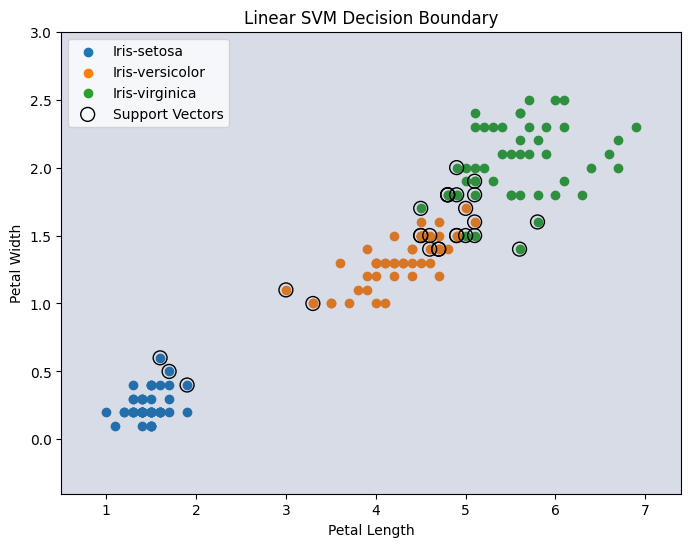

In [15]:
# Visualize SVM Decision Boundary

X_vis = df[['PetalLengthCm', 'PetalWidthCm']]
y_vis = y

X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis, y_vis, test_size=0.3, random_state=42
)

scaler_vis = StandardScaler()

X_train_vis = scaler_vis.fit_transform(X_train_vis)
X_test_vis = scaler_vis.transform(X_test_vis)

svm_vis = SVC(kernel='linear')
svm_vis.fit(X_train_vis, y_train_vis)

print("SVM trained successfully.")
print("Support Vectors:")
print(svm_vis.support_vectors_)

# Plot SVM Decision Boundary

plt.figure(figsize=(8, 6))

# Plot the data points
for species in y_vis.unique():
    data = X_vis[y_vis == species]
    plt.scatter(
        data['PetalLengthCm'],
        data['PetalWidthCm'],
        label=species
    )

# Create a grid
x_min = X_vis['PetalLengthCm'].min() - 0.5
x_max = X_vis['PetalLengthCm'].max() + 0.5
y_min = X_vis['PetalWidthCm'].min() - 0.5
y_max = X_vis['PetalWidthCm'].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

# Scale grid points
grid = scaler_vis.transform(
    np.c_[xx.ravel(), yy.ravel()]
)

# Predict classes
Z = svm_vis.predict(grid)
Z = pd.factorize(y_vis)[0][np.array([list(y_vis.unique()).index(i) for i in Z])]

Z = Z.reshape(xx.shape)

# Plot decision regions
plt.contourf(xx, yy, Z, alpha=0.2)

# Plot support vectors
support = scaler_vis.inverse_transform(svm_vis.support_vectors_)

plt.scatter(
    support[:, 0],
    support[:, 1],
    s=100,
    facecolors='none',
    edgecolors='black',
    label='Support Vectors'
)

plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.title('Linear SVM Decision Boundary')
plt.legend()
plt.show()

# Task 8: Normal Linear Classification Boundary

For comparison, we use **Logistic Regression** as a normal linear classifier.

Train a Logistic Regression model using the same two features and visualize its decision boundary.

---

In [16]:
# Normal Linear Classification Boundary

log_model = LogisticRegression()

log_model.fit(X_train_vis, y_train_vis)

y_log_pred = log_model.predict(X_test_vis)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


# Task 9: Compare SVM and Normal Boundary

Plot both the **SVM** and **Logistic Regression** decision boundaries on the same graph.

Compare how the two classifiers separate the different classes.

---

In [12]:
# Normal Linear Classification Boundary

log_model = LogisticRegression()

log_model.fit(X_train_vis, y_train_vis)

y_log_pred = log_model.predict(X_test_vis)

print("Logistic Regression trained successfully.")


Logistic Regression trained successfully.


# Task 10: Compare Performance

Compare the performance of the **Linear SVM** and **Logistic Regression** using:

- Accuracy
- Confusion Matrix
- Classification Report

---

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


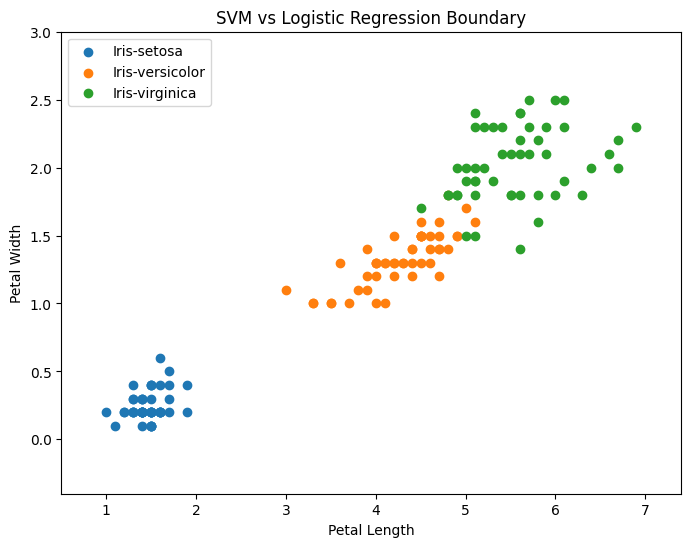

In [18]:
# Task 9: Compare SVM and Normal Linear Boundary

plt.figure(figsize=(8, 6))

# Plot data points
for species in y_vis.unique():
    data = X_vis[y_vis == species]
    plt.scatter(
        data['PetalLengthCm'],
        data['PetalWidthCm'],
        label=species
    )

# Create grid
xx, yy = np.meshgrid(
    np.linspace(X_vis['PetalLengthCm'].min() - 0.5,
                X_vis['PetalLengthCm'].max() + 0.5, 500),
    np.linspace(X_vis['PetalWidthCm'].min() - 0.5,
                X_vis['PetalWidthCm'].max() + 0.5, 500)
)

grid = scaler_vis.transform(np.c_[xx.ravel(), yy.ravel()])

# SVM boundary
svm_pred = svm_vis.predict(grid)
svm_pred = pd.factorize(y_vis)[0][
    [list(y_vis.unique()).index(i) for i in svm_pred]
]
svm_pred = svm_pred.reshape(xx.shape)

# Logistic Regression boundary
log_pred = log_model.predict(grid)
log_pred = pd.factorize(y_vis)[0][
    [list(y_vis.unique()).index(i) for i in log_pred]
]
log_pred = log_pred.reshape(xx.shape)

# Draw both boundaries
plt.contour(xx, yy, svm_pred, levels=[0.5, 1.5],
            linestyles='-', linewidths=2)

plt.contour(xx, yy, log_pred, levels=[0.5, 1.5],
            linestyles='--', linewidths=2)

plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.title('SVM vs Logistic Regression Boundary')
plt.legend()
plt.show()

# Conclusion

The experiment successfully demonstrated the implementation of **Support Vector Machine (SVM)** using the Iris dataset. The dataset was preprocessed and standardized before training the model.

A **Linear SVM** was implemented and its decision boundary was visualized along with the support vectors. A normal linear classification boundary using **Logistic Regression** was also visualized for comparison.